# 2023 — Aligning Models with Preferences: RLHF → DPO

**Papers:** Christiano et al., *"Deep RL from Human Preferences"* (2017); Ouyang et al., *InstructGPT* (2022), the **RLHF** pipeline behind ChatGPT; Rafael Rafailov et al., *"Direct Preference Optimization: Your Language Model is Secretly a Reward Model"* (DPO, 2023).

People can't easily write down the "right" answer, but they can say which of two answers is **better**. RLHF:
1. collect preference pairs $(x, y_w, y_l)$: answer $y_w$ is preferred over $y_l$
2. fit a **reward model** with the Bradley–Terry loss $-\log\sigma(r(y_w) - r(y_l))$
3. optimise the policy with RL (PPO) to maximise reward minus a KL penalty to the starting model: $\max_\pi \mathbb E[r] - \beta\,\mathrm{KL}(\pi\|\pi_{ref})$

**DPO** showed that this KL-regularised objective has a closed-form optimal policy, so the reward model and the RL loop can be skipped. You train directly on the pairs:

$$\mathcal L_{DPO} = -\log\sigma\Big(\beta\Big[\log\frac{\pi_\theta(y_w)}{\pi_{ref}(y_w)} - \log\frac{\pi_\theta(y_l)}{\pi_{ref}(y_l)}\Big]\Big)$$

It's simple and stable, and DPO plus its variants (IPO, KTO, SimPO, ...) became standard for preference tuning. RL with *verifiable* rewards (notebook 48) handles tasks where correctness can be checked.

**Toy setup:** a small language model writes 8-token "answers" over a 12-token vocabulary. A hidden "human" prefers answers with more **rising steps** ($y_{t+1} > y_t$), plus noise. We train with DPO on pairs sampled from the reference model.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
import copy

PyTorch 2.15.0 | device: mps


In [2]:
V, L = 12, 8
BOS = V
class LM(nn.Module):
    def __init__(self, d=128):
        super().__init__(); self.emb = nn.Embedding(V + 1, d); self.rnn = nn.GRU(d, d, batch_first=True); self.head = nn.Linear(d, V)
    def forward(self, seq): return self.head(self.rnn(self.emb(seq))[0])
    @torch.no_grad()
    def sample(self, n, temperature=1.0):
        seq = torch.full((n, 1), BOS, device=device)
        for _ in range(L): seq = torch.cat([seq, torch.multinomial(F.softmax(self(seq)[:, -1] / temperature, -1), 1)], 1)
        return seq[:, 1:]
    def logprob(self, y):
        inp = torch.cat([torch.full((len(y), 1), BOS, device=device), y[:, :-1]], 1)
        return F.log_softmax(self(inp), -1).gather(-1, y[..., None]).squeeze(-1).sum(-1)

def hidden_reward(y): return (y[:, 1:] > y[:, :-1]).float().sum(-1)       # number of rising steps, 0..7

## Step 0: a "pre-trained / SFT" reference model
Train on random sequences, so it starts with no preference (mean reward ≈ 3.2).

In [3]:
seed_everything(0)
ref = LM().to(device); opt = torch.optim.Adam(ref.parameters(), lr=2e-3)
for _ in range(400):
    y = torch.randint(0, V, (128, L), device=device)
    loss = -ref.logprob(y).mean(); opt.zero_grad(); loss.backward(); opt.step()
ref.eval()
print(f"reference model: mean hidden reward of samples = {hidden_reward(ref.sample(2000)).mean():.2f} / 7")

reference model: mean hidden reward of samples = 3.21 / 7


## Step 1: collect preference pairs
Sample two answers from the reference model and let a noisy "human" choose the better one using the Bradley–Terry model $P(a \succ b) = \sigma(r_a - r_b)$.

In [4]:
def make_pairs(n):
    a, b = ref.sample(n), ref.sample(n)
    p_a = torch.sigmoid(hidden_reward(a) - hidden_reward(b))
    a_wins = torch.rand(n, device=device) < p_a
    yw = torch.where(a_wins[:, None], a, b); yl = torch.where(a_wins[:, None], b, a)
    return yw, yl
YW, YL = make_pairs(8000)
print(f"8000 pairs; the human label agrees with the true reward ordering {(hidden_reward(YW) >= hidden_reward(YL)).float().mean():.0%} of the time (noisy, like real annotators)")

8000 pairs; the human label agrees with the true reward ordering 85% of the time (noisy, like real annotators)


## Step 2: DPO

beta=0.05  final mean reward 5.27 / 7   KL(pi || ref) = 12.62 nats
beta=0.2   final mean reward 5.41 / 7   KL(pi || ref) = 5.70 nats
beta=1.0   final mean reward 3.94 / 7   KL(pi || ref) = 0.53 nats


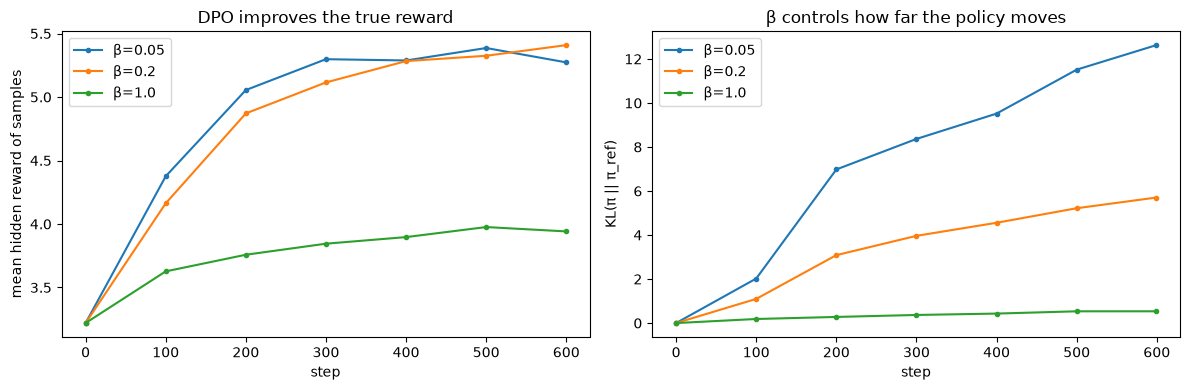

In [5]:
def train_dpo(beta, steps=600):
    seed_everything(0)
    pi = copy.deepcopy(ref).train(); opt = torch.optim.Adam(pi.parameters(), lr=5e-4); hist = []
    with torch.no_grad(): ref_w, ref_l = ref.logprob(YW), ref.logprob(YL)
    for s in range(steps):
        idx = torch.randint(0, len(YW), (128,), device=device)
        logits = beta * ((pi.logprob(YW[idx]) - ref_w[idx]) - (pi.logprob(YL[idx]) - ref_l[idx]))   # implicit reward margin
        loss = -F.logsigmoid(logits).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if s % 100 == 0 or s == steps - 1:
            pi.eval()
            with torch.no_grad():
                y = pi.sample(1000); kl = (pi.logprob(y) - ref.logprob(y)).mean().item()   # Monte Carlo KL(pi || ref)
            hist.append((s, hidden_reward(y).mean().item(), kl)); pi.train()
    return pi, hist

runs = {beta: train_dpo(beta) for beta in [0.05, 0.2, 1.0]}
for beta, (pi, h) in runs.items():
    print(f"beta={beta:<5} final mean reward {h[-1][1]:.2f} / 7   KL(pi || ref) = {h[-1][2]:.2f} nats")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for beta, (pi, h) in runs.items():
    s, r, kl = zip(*h); axes[0].plot(s, r, marker=".", label=f"β={beta}"); axes[1].plot(s, kl, marker=".", label=f"β={beta}")
axes[0].set(xlabel="step", ylabel="mean hidden reward of samples", title="DPO improves the true reward"); axes[0].legend()
axes[1].set(xlabel="step", ylabel="KL(π || π_ref)", title="β controls how far the policy moves"); axes[1].legend()
plt.tight_layout(); plt.show()

## The policy is secretly a reward model
DPO's implicit reward $\hat r(y) = \beta\log\frac{\pi_\theta(y)}{\pi_{ref}(y)}$ should rank new answers the way the hidden reward does, even though no reward model was ever trained.

In [6]:
pi = runs[0.2][0]; pi.eval()
with torch.no_grad():
    y = ref.sample(3000); implicit = 0.2 * (pi.logprob(y) - ref.logprob(y)); true = hidden_reward(y)
from scipy.stats import spearmanr
print(f"Spearman correlation between implicit and hidden reward: {spearmanr(implicit.cpu(), true.cpu())[0]:.2f}")
print("samples after DPO:", pi.sample(4).tolist())

Spearman correlation between implicit and hidden reward: 0.87


samples after DPO: [[2, 4, 11, 2, 4, 8, 9, 10], [2, 3, 4, 9, 11, 7, 10, 1], [0, 5, 10, 11, 2, 3, 5, 11], [0, 5, 0, 4, 6, 11, 7, 9]]
